In [1]:
print("Cognifyz Data Analytics Internship")
print("Task: Top Cuisines")
print("Notebook is ready!")

Cognifyz Data Analytics Internship
Task: Top Cuisines
Notebook is ready!


In [8]:
import os

print(os.path.exists("zomato.csv"))
print(os.path.getsize("zomato.csv"))

True
2257316


In [9]:
import pandas as pd

df = pd.read_csv("zomato.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [10]:
print(df["Cuisines"].head(10))
print("\nMissing cuisine values:", df["Cuisines"].isnull().sum())

0            French, Japanese, Desserts
1                              Japanese
2      Seafood, Asian, Filipino, Indian
3                       Japanese, Sushi
4                      Japanese, Korean
5                               Chinese
6                       Asian, European
7    Seafood, Filipino, Asian, European
8               European, Asian, Indian
9                              Filipino
Name: Cuisines, dtype: str

Missing cuisine values: 9


In [11]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

print("Missing cuisines after cleaning:", df["Cuisines"].isnull().sum())

Missing cuisines after cleaning: 0


In [12]:
cuisine_counts = (
    df["Cuisines"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)

print("Top 10 Cuisines:")
display(cuisine_counts.head(10))

Top 10 Cuisines:


Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64

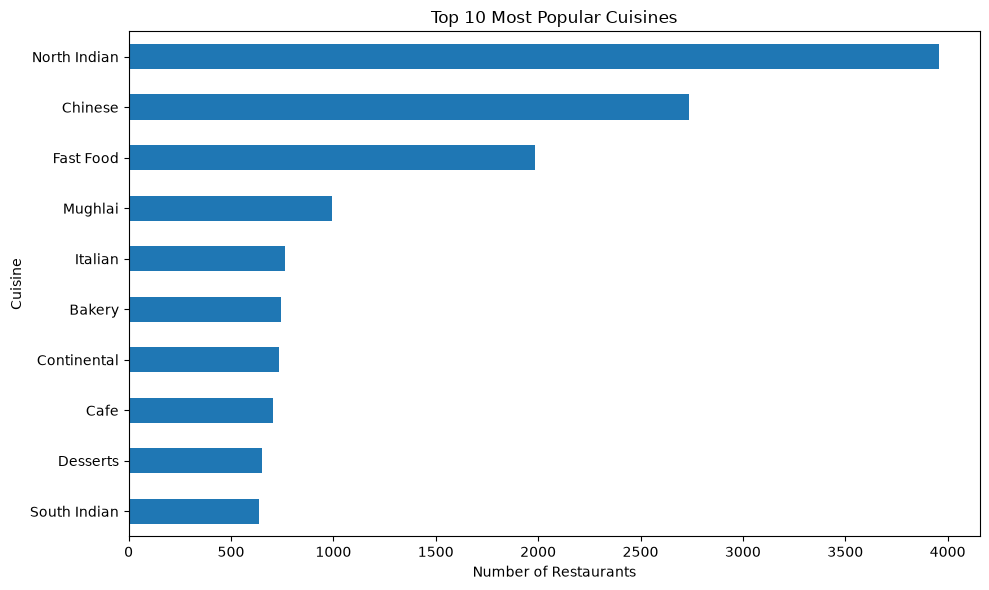

In [13]:
import matplotlib.pyplot as plt

top_10 = cuisine_counts.head(10)

plt.figure(figsize=(10, 6))
top_10.sort_values().plot(kind="barh")

plt.title("Top 10 Most Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

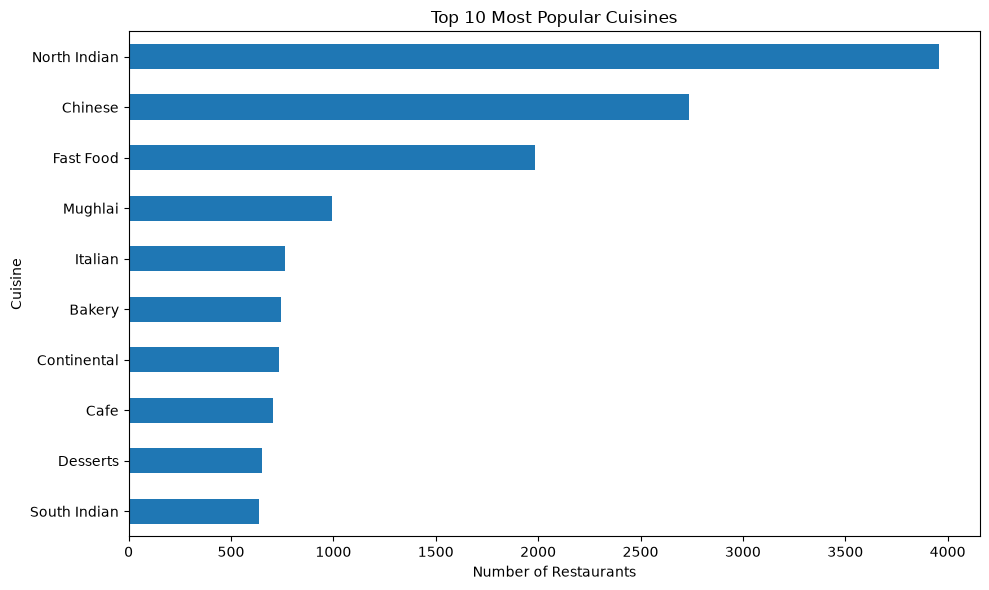

In [14]:
plt.figure(figsize=(10, 6))
top_10.sort_values().plot(kind="barh")

plt.title("Top 10 Most Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.tight_layout()

plt.savefig("Top_10_Cuisines.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
top_10.to_csv("Top_10_Cuisines.csv", header=True)

print("Top cuisines results saved successfully!")

Top cuisines results saved successfully!


In [16]:
total_restaurants = len(df)

top_3 = cuisine_counts.head(3)

results = pd.DataFrame({
    "Cuisine": top_3.index,
    "Restaurant Count": top_3.values,
    "Percentage (%)": (
        top_3.values / total_restaurants * 100
    ).round(2)
})

display(results)

,Cuisine,Restaurant Count,Percentage (%)
0,North Indian,3960,41.46
1,Chinese,2735,28.64
2,Fast Food,1986,20.79


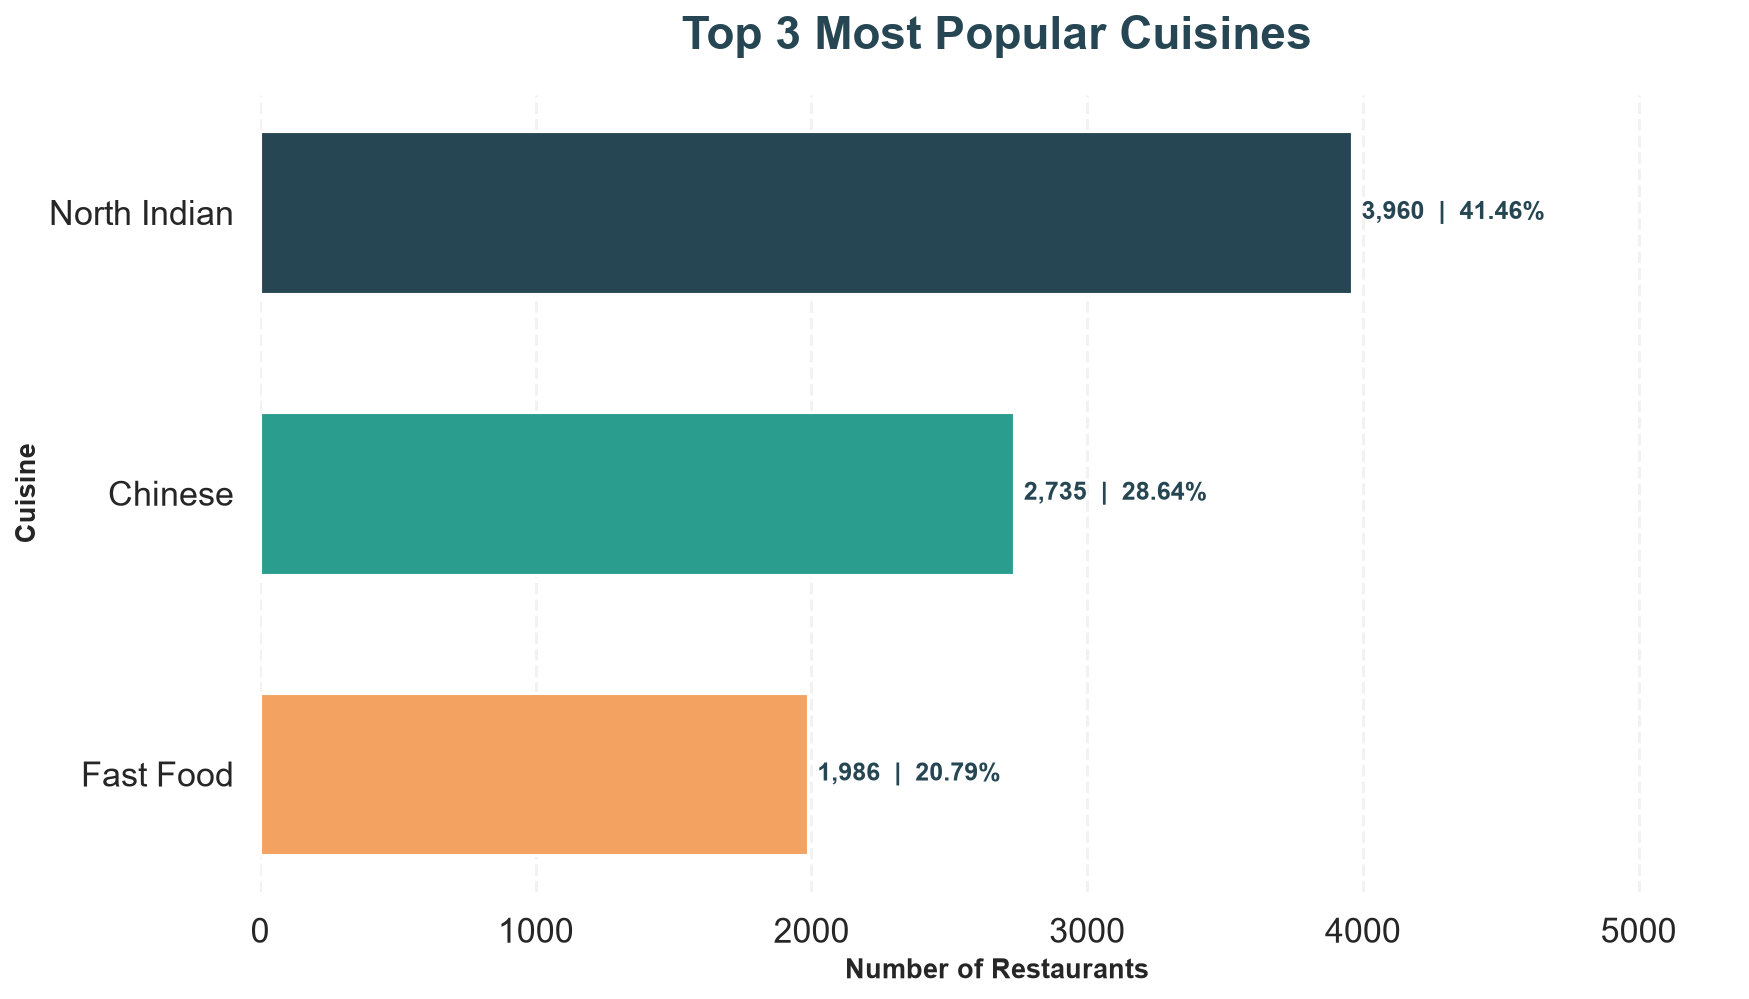

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Premium chart theme
sns.set_theme(style="whitegrid", context="talk")

# Prepare the top 3 results
chart_data = results.sort_values(
    "Restaurant Count", ascending=True
)

# Create figure
fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

colors = ["#F4A261", "#2A9D8F", "#264653"]

bars = ax.barh(
    chart_data["Cuisine"],
    chart_data["Restaurant Count"],
    color=colors,
    height=0.58
)

# Add restaurant counts and percentages
for bar, count, percentage in zip(
    bars,
    chart_data["Restaurant Count"],
    chart_data["Percentage (%)"]
):
    ax.text(
        bar.get_width() + 35,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}  |  {percentage:.2f}%",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="#264653"
    )

ax.set_title(
    "Top 3 Most Popular Cuisines",
    fontsize=22,
    fontweight="bold",
    color="#264653",
    pad=22
)

ax.set_xlabel(
    "Number of Restaurants",
    fontsize=13,
    fontweight="bold"
)
ax.set_ylabel("Cuisine", fontsize=13, fontweight="bold")

ax.set_xlim(0, chart_data["Restaurant Count"].max() * 1.35)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.savefig(
    "Top_3_Cuisines_Premium.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### Insights: Top Cuisines
- North Indian is the most common cuisine with 3,960 restaurants (41.46%).
- Chinese is second with 2,735 restaurants (28.64%), followed by Fast Food with 1,986 restaurants (20.79%).
- The top 3 cuisines together cover a large share of the restaurants in the dataset.

In [18]:
print("=" * 55)
print("COGNIFYZ DATA ANALYTICS — TASK 1")
print("TOP CUISINES: KEY FINDINGS")
print("=" * 55)

top_cuisine = results.iloc[0]
second_cuisine = results.iloc[1]
third_cuisine = results.iloc[2]

print(f"\n1. Most popular cuisine: {top_cuisine['Cuisine']}")
print(f"   Restaurant count: {top_cuisine['Restaurant Count']:,}")
print(f"   Dataset percentage: {top_cuisine['Percentage (%)']:.2f}%")

print(f"\n2. Second most popular: {second_cuisine['Cuisine']}")
print(f"   Restaurant count: {second_cuisine['Restaurant Count']:,}")

print(f"\n3. Third most popular: {third_cuisine['Cuisine']}")
print(f"   Restaurant count: {third_cuisine['Restaurant Count']:,}")

print("\nBUSINESS INSIGHT")
print(
    f"{top_cuisine['Cuisine']} has the highest restaurant count "
    "among the cuisines identified in this analysis."
)
print(
    "Restaurants can use cuisine popularity as one input when "
    "planning menus and studying local competition."
)

print("\nNote: Percentages use the total_restaurants denominator.")
print("=" * 55)

COGNIFYZ DATA ANALYTICS — TASK 1
TOP CUISINES: KEY FINDINGS

1. Most popular cuisine: North Indian
   Restaurant count: 3,960
   Dataset percentage: 41.46%

2. Second most popular: Chinese
   Restaurant count: 2,735

3. Third most popular: Fast Food
   Restaurant count: 1,986

BUSINESS INSIGHT
North Indian has the highest restaurant count among the cuisines identified in this analysis.
Restaurants can use cuisine popularity as one input when planning menus and studying local competition.

Note: Percentages use the total_restaurants denominator.


In [19]:
import os

print("File exists:", os.path.exists("zomato.csv"))

with open("zomato.csv", "rb") as file:
    print("First 20 bytes:", file.read(20))

File exists: True
First 20 bytes: b'Restaurant ID,Restau'


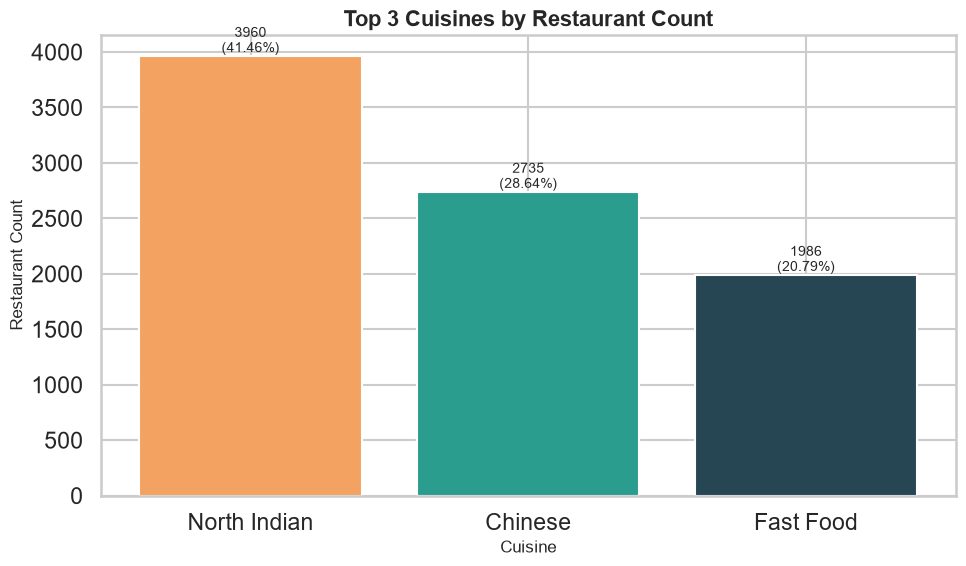

In [41]:
# Save Top 3 Cuisines chart

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results["Cuisine"],
    results["Restaurant Count"],
    color=["#F4A261", "#2A9D8F", "#264653"]
)

plt.title(
    "Top 3 Cuisines by Restaurant Count",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Cuisine", fontsize=12)
plt.ylabel("Restaurant Count", fontsize=12)

for bar, count, percentage in zip(
    bars,
    results["Restaurant Count"],
    results["Percentage (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 40,
        f"{count}\n({percentage:.2f}%)",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.savefig("Top_3_Cuisines.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
plt.savefig("Top_3_Cuisines.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [22]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (9551, 21)
Columns: ['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

LEVEL 1 — TASK 2: CITY ANALYSIS

In [25]:
# Task 2: City Analysis
# Find the city with the highest number of restaurants

city_counts = df["City"].value_counts()

print("TOP 10 CITIES BY NUMBER OF RESTAURANTS")
print(city_counts.head(10))

TOP 10 CITIES BY NUMBER OF RESTAURANTS
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64


In [26]:
# Calculate average rating for each city

city_ratings = (
    df.groupby("City")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)

print("TOP 10 CITIES BY AVERAGE RATING")
print(city_ratings.head(10).round(2))

TOP 10 CITIES BY AVERAGE RATING
City
Inner City          4.90
Quezon City         4.80
Makati City         4.65
Pasig City          4.63
Mandaluyong City    4.62
Beechworth          4.60
London              4.54
Taguig City         4.53
Secunderabad        4.50
Lincoln             4.50
Name: Aggregate rating, dtype: float64


In [27]:
# Combine restaurant count and average rating for each city

city_analysis = df.groupby("City").agg(
    Restaurant_Count=("Restaurant ID", "count"),
    Average_Rating=("Aggregate rating", "mean")
)

city_analysis = city_analysis.sort_values(
    by="Restaurant_Count",
    ascending=False
)

print("TOP 10 CITIES BY RESTAURANT COUNT")
print(city_analysis.head(10).round(2))

TOP 10 CITIES BY RESTAURANT COUNT
              Restaurant_Count  Average_Rating
City                                          
New Delhi                 5473            2.44
Gurgaon                   1118            2.65
Noida                     1080            2.04
Faridabad                  251            1.87
Ghaziabad                   25            2.85
Bhubaneshwar                21            3.98
Lucknow                     21            4.20
Guwahati                    21            4.19
Ahmedabad                   21            4.16
Amritsar                    21            3.69


In [28]:
# Top 10 cities by average rating
# Consider cities with at least 20 restaurant records

city_rating_filtered = city_analysis[
    city_analysis["Restaurant_Count"] >= 20
].sort_values(
    by="Average_Rating",
    ascending=False
)

print("TOP 10 CITIES BY AVERAGE RATING")
print(city_rating_filtered.head(10).round(2))

TOP 10 CITIES BY AVERAGE RATING
                Restaurant_Count  Average_Rating
City                                            
London                        20            4.54
Orlando                       20            4.47
Tampa Bay                     20            4.41
Rest of Hawaii                20            4.41
Bangalore                     20            4.38
Dubai                         20            4.37
Chennai                       20            4.31
Ankara                        20            4.30
Abu Dhabi                     20            4.30
Auckland                      20            4.28


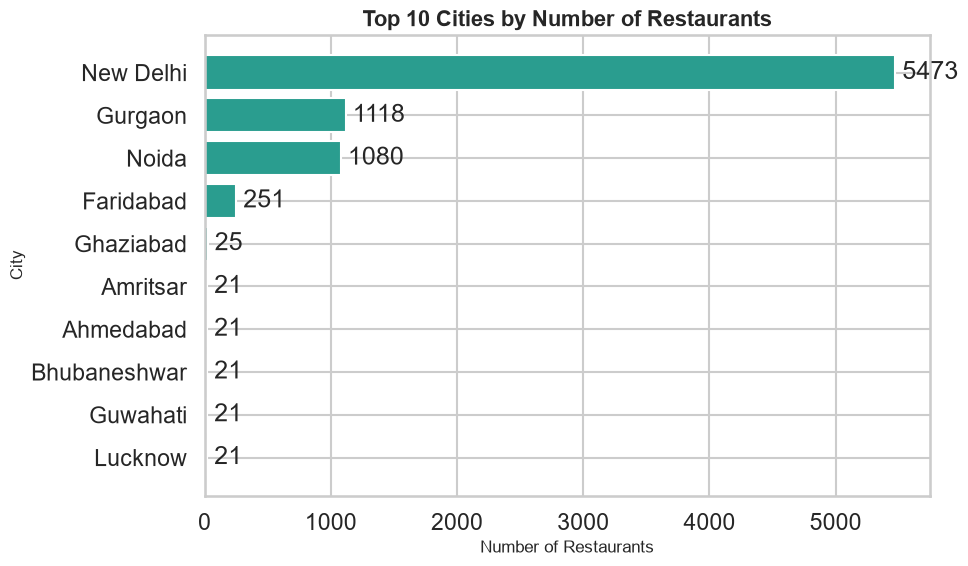

In [29]:
import matplotlib.pyplot as plt

top_cities = city_analysis.head(10).sort_values(
    "Restaurant_Count",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_cities.index,
    top_cities["Restaurant_Count"],
    color="#2A9D8F"
)

plt.title(
    "Top 10 Cities by Number of Restaurants",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Number of Restaurants", fontsize=12)
plt.ylabel("City", fontsize=12)

for i, value in enumerate(top_cities["Restaurant_Count"]):
    plt.text(value, i, f" {value}", va="center")

plt.tight_layout()
plt.savefig("Top_10_Cities.png", dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# Save city analysis results to CSV

city_analysis.to_csv("City_Analysis_Results.csv")

print("City analysis results saved successfully!")
print("File name: City_Analysis_Results.csv")

City analysis results saved successfully!
File name: City_Analysis_Results.csv


In [31]:
# Key findings for City Analysis

top_city = city_analysis["Restaurant_Count"].idxmax()
top_count = city_analysis["Restaurant_Count"].max()

top_rated_city = city_rating_filtered["Average_Rating"].idxmax()
top_rating = city_rating_filtered.loc[
    top_rated_city, "Average_Rating"
]

print("=" * 45)
print("COGNIFYZ — TASK 2: CITY ANALYSIS")
print("=" * 45)
print(f"Most restaurants: {top_city} ({top_count})")
print(
    f"Highest average rating among cities "
    f"with 20+ restaurants: {top_rated_city} "
    f"({top_rating:.2f})"
)
print("=" * 45)

COGNIFYZ — TASK 2: CITY ANALYSIS
Most restaurants: New Delhi (5473)
Highest average rating among cities with 20+ restaurants: London (4.54)


### Insights: City Analysis
- New Delhi has the most restaurants (5,473), followed by Gurgaon (1,118) and Noida (1,080).
- London has the highest average rating (4.54) among cities with 20+ restaurants, followed by Orlando (4.47) and Tampa Bay (4.41).
- Delhi NCR cities have low average ratings (New Delhi 2.44, Noida 2.04, Faridabad 1.87), well below the top-rated cities.

In [34]:
 #LEVEL 1 — TASK 3: PRICE RANGE DISTRIBUTION

In [35]:
# Task 3: Price Range Distribution

price_counts = df["Price range"].value_counts().sort_index()

print("PRICE RANGE DISTRIBUTION")
print("------------------------")
print(price_counts)

print("\nTotal restaurants:", price_counts.sum())

PRICE RANGE DISTRIBUTION
------------------------
Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

Total restaurants: 9551


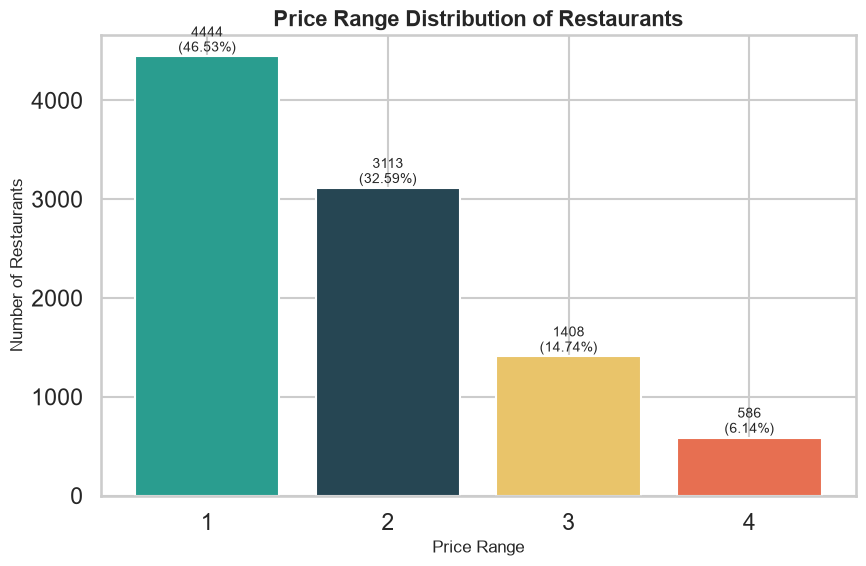

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

bars = plt.bar(
    price_counts.index.astype(str),
    price_counts.values,
    color=["#2A9D8F", "#264653", "#E9C46A", "#E76F51"],
    edgecolor="white"
)

plt.title(
    "Price Range Distribution of Restaurants",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Price Range", fontsize=12)
plt.ylabel("Number of Restaurants", fontsize=12)

for bar, count in zip(bars, price_counts.values):
    percentage = count / price_counts.sum() * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{count}\n({percentage:.2f}%)",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.savefig("Price_Range_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Insights: Price Range Distribution
- Price range 1 (budget) is the most common with 4,444 restaurants (46.5%).
- Price range 2 follows with 3,113 restaurants (32.6%).
- Price range 4 (premium) is the least common with only 586 restaurants (6.1%).
- Most restaurants are budget to mid-range, so affordable dining dominates the market.

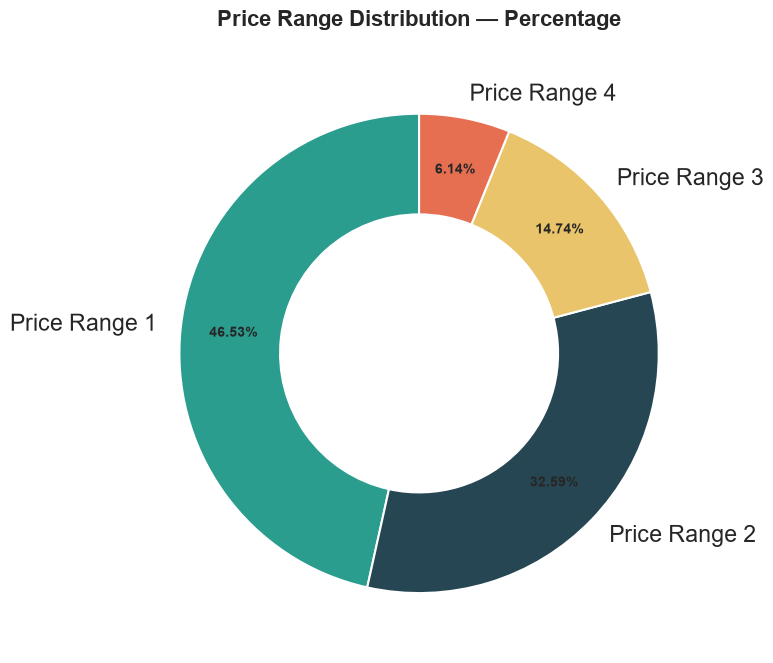

In [37]:
# Donut chart for Price Range Distribution

import matplotlib.pyplot as plt

labels = [f"Price Range {i}" for i in price_counts.index]
colors = ["#2A9D8F", "#264653", "#E9C46A", "#E76F51"]

plt.figure(figsize=(8, 8))

wedges, texts, autotexts = plt.pie(
    price_counts.values,
    labels=labels,
    colors=colors,
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)

plt.title(
    "Price Range Distribution — Percentage",
    fontsize=16,
    fontweight="bold",
    pad=20
)

for text in autotexts:
    text.set_fontsize(10)
    text.set_fontweight("bold")

plt.tight_layout()
plt.savefig("Price_Range_Donut.png", dpi=300, bbox_inches="tight")
plt.show()

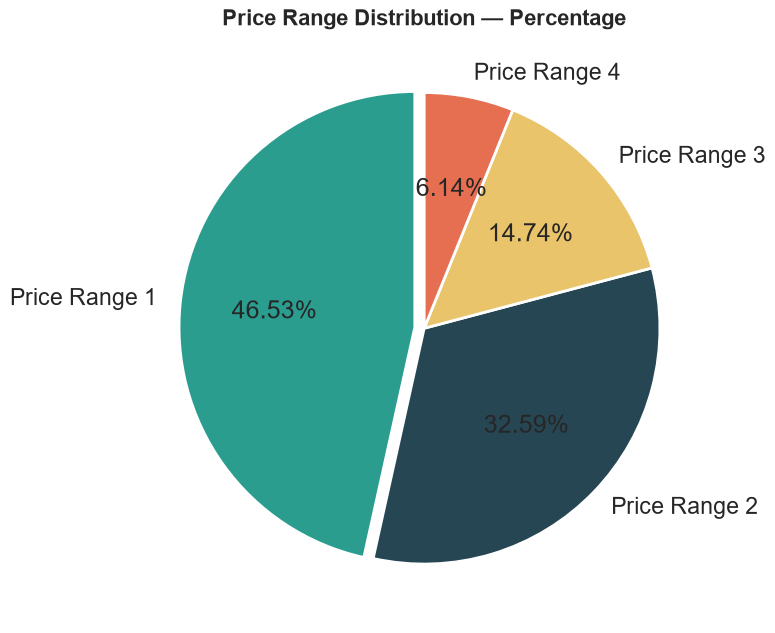

In [38]:
# Pie Chart: Price Range Distribution

plt.figure(figsize=(8, 8))

plt.pie(
    price_counts.values,
    labels=[f"Price Range {i}" for i in price_counts.index],
    autopct="%1.2f%%",
    startangle=90,
    colors=["#2A9D8F", "#264653", "#E9C46A", "#E76F51"],
    explode=(0.04, 0, 0, 0),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title(
    "Price Range Distribution — Percentage",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("Price_Range_Pie.png", dpi=300, bbox_inches="tight")
plt.show()

In [39]:
# Create a summary table

price_summary = price_counts.reset_index()
price_summary.columns = ["Price Range", "Restaurant Count"]

price_summary["Percentage (%)"] = (
    price_summary["Restaurant Count"]
    / price_summary["Restaurant Count"].sum()
    * 100
).round(2)

# Save results to CSV
price_summary.to_csv("Price_Range_Distribution.csv", index=False)

print("Price Range analysis saved successfully!")
print(price_summary)

Price Range analysis saved successfully!
   Price Range  Restaurant Count  Percentage (%)
0            1              4444           46.53
1            2              3113           32.59
2            3              1408           14.74
3            4               586            6.14


In [40]:
# Key findings: Price Range Distribution

highest_range = price_summary.loc[
    price_summary["Restaurant Count"].idxmax()
]

print("=" * 45)
print("COGNIFYZ — LEVEL 1, TASK 3")
print("PRICE RANGE DISTRIBUTION")
print("=" * 45)

print(
    f"Most common price range: "
    f"{highest_range['Price Range']}"
)
print(
    f"Restaurant count: "
    f"{highest_range['Restaurant Count']}"
)
print(
    f"Percentage of restaurants: "
    f"{highest_range['Percentage (%)']:.2f}%"
)
print("=" * 45)

COGNIFYZ — LEVEL 1, TASK 3
PRICE RANGE DISTRIBUTION
Most common price range: 1.0
Restaurant count: 4444.0
Percentage of restaurants: 46.53%
